# Hybrid CNN: fusion design (H1–H3)
Two-branch hybrid (VGG16 + ConvNeXtTiny) with concatenation (H1), gated fusion (H2) and gated fusion with auxiliary classifiers (H3), on all four crops.

## 1. GPU check

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Settings + Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q imagehash
from pathlib import Path
import os, json, time, gc, hashlib, subprocess
import numpy as np, pandas as pd, psutil, imagehash
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

PROJECT   = Path('/content/drive/MyDrive/thesis')
ZIP_PATH  = PROJECT / 'data/raw/agri_vision.zip'
RICE_ZIP  = PROJECT / 'data/raw/riceleafbd.zip'
VERSIONS  = ['H3', 'H1', 'H2']                                # H3 first: the full model gives the main answer
CROPS     = ['Tomato', 'Papaya', 'Bottle_Gourd', 'Rice']
RUN_NAME  = 'hybrid'                                          # results: experiments/<crop>/hybrid/
REFERENCE = {'Tomato': 'run05_balanced300_moderateaug', 'Papaya': 'run05_balanced_moderateaug',
             'Bottle_Gourd': 'run05_balanced_moderateaug', 'Rice': 'run05_balanced_moderateaug'}   # single CNNs, same setting
IMG_SIZE, TARGET_PER_CLASS = 224, 300
FOLD, SEED, N_FOLDS = 0, 42, 5
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
print('Agri-Vision zip found:', ZIP_PATH.exists(), '| Rice zip found:', RICE_ZIP.exists())

Mounted at /content/drive
Agri-Vision zip found: True | Rice zip found: True


## 3. Agri-Vision: unzip to local disk

In [3]:
import shutil
UNZIP_DIR = Path('/content/data/agri_vision')
print('Agri-Vision zip found in Drive:', ZIP_PATH.exists(), ZIP_PATH)
assert ZIP_PATH.exists(), 'Zip not found: check the file name and folder in Google Drive'

def find_orig():
    return [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()]

if not find_orig():                      # missing or incomplete unzip -> start again cleanly
    shutil.rmtree(UNZIP_DIR, ignore_errors=True)
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

found = find_orig()
if not found:
    print('Still no "Original" folder. Top folders inside the zip:')
    for p in sorted(UNZIP_DIR.rglob('*')):
        if p.is_dir() and len(p.relative_to(UNZIP_DIR).parts) <= 3:
            print('   ', p.relative_to(UNZIP_DIR))
    raise SystemExit('Original images folder not found')
ORIG_DIR = found[0]
print('Original images folder:', ORIG_DIR)

Agri-Vision zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/agri_vision.zip
Original images folder: /content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset


## 4. Agri-Vision: audit, clean and folds

In [4]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
rows = []
for p in tqdm(sorted(q for q in ORIG_DIR.rglob('*') if q.suffix.lower() in IMG_EXT), desc='Hashing'):
    parts = p.relative_to(ORIG_DIR).parts
    rec = {'rel_path': '/'.join(parts), 'split': parts[0], 'label_raw': parts[-2]}
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rec['phash'] = str(imagehash.phash(im.convert('RGB')))
        rec['md5'] = hashlib.md5(p.read_bytes()).hexdigest()
        rec['corrupt'] = False
    except Exception:
        rec['corrupt'] = True
    rows.append(rec)
df = pd.DataFrame(rows).sort_values('rel_path').reset_index(drop=True)
df['label'] = df.label_raw.replace({'Tomato_Downy Mildew': 'Tomato_Downy_Mildew', 'Zucchini_Downy_Midew': 'Zucchini_Downy_Mildew'})
df['crop'] = df.label.str.extract(r'^(Bottle_Gourd|Papaya|Tomato|Zucchini)', expand=False)
df['keep'], df['reason'] = True, ''

def drop(mask, reason):
    m = mask & df.keep
    df.loc[m, 'keep'], df.loc[m, 'reason'] = False, reason
    print(f'{reason:24s} removed {int(m.sum()):5d}   remaining {int(df.keep.sum()):5d}')

drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
drop(df.crop.eq('Zucchini'), 'excluded_zucchini')

kept = df[df.keep].copy()
kept['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(kept, kept.label, groups=kept.phash)):
    kept.iloc[tst, kept.columns.get_loc('fold')] = k
assert kept.md5.is_unique and kept.groupby('phash').fold.nunique().max() == 1
AV_KEPT, AV_DIR = kept, ORIG_DIR
print(kept.groupby('crop').size().rename('clean images').to_string())

Hashing:   0%|          | 0/5246 [00:00<?, ?it/s]

unreadable               removed     0   remaining  5246
label_conflict_exact     removed   754   remaining  4492
duplicate_copy           removed   463   remaining  4029
label_conflict_near      removed    18   remaining  4011
excluded_zucchini        removed   262   remaining  3749
crop
Bottle_Gourd    1491
Papaya          1463
Tomato           795


## 5. RiceLeafBD: unzip, read labels, audit, clean and folds

In [5]:
import shutil
RICE_ROOT = Path('/content/data/riceleafbd')
print('Rice zip found in Drive:', RICE_ZIP.exists(), RICE_ZIP)
assert RICE_ZIP.exists(), 'Rice zip not found: check the file name and folder in Google Drive'
if not RICE_ROOT.exists() or not any(q.suffix.lower() in IMG_EXT for q in RICE_ROOT.rglob('*')):
    shutil.rmtree(RICE_ROOT, ignore_errors=True)
    RICE_ROOT.mkdir(parents=True)
    !unzip -q "{RICE_ZIP}" -d "{RICE_ROOT}"
    for inner in list(RICE_ROOT.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

print('Folder tree (folders with images):')
for p in sorted(q for q in RICE_ROOT.rglob('*') if q.is_dir()):
    n = sum(1 for f in p.iterdir() if f.suffix.lower() in IMG_EXT)
    if n or len(p.relative_to(RICE_ROOT).parts) <= 2:
        print('   ' * (len(p.relative_to(RICE_ROOT).parts) - 1) + f'{p.name}/  ({n} images)')
print('CSV files:', [str(c.relative_to(RICE_ROOT)) for c in RICE_ROOT.rglob('*.csv')])

RICE_CLASSES = [('tungro', 'Rice_Tungro'), ('brown', 'Rice_Brown_Spot'),
                ('bacterial', 'Rice_Bacterial_Leaf_Blight'), ('blight', 'Rice_Bacterial_Leaf_Blight'),
                ('healthy', 'Rice_Healthy')]
def rice_label(text):
    t = str(text).lower().replace('_', ' ').replace('-', ' ')
    for key, lab in RICE_CLASSES:
        if key in t:
            return lab
    return None

files = sorted(q for q in RICE_ROOT.rglob('*') if q.suffix.lower() in IMG_EXT
               and not any('augment' in part.lower() for part in q.relative_to(RICE_ROOT).parts))
r = pd.DataFrame({'rel_path': ['/'.join(q.relative_to(RICE_ROOT).parts) for q in files]})
r['label'] = [next((l for l in (rice_label(x) for x in reversed(q.relative_to(RICE_ROOT).parts[:-1])) if l), None) for q in files]
print(f'\n{len(r)} images found; labelled from folder names: {r.label.notna().sum()}')

if r.label.isna().mean() > 0.5:                                    # folders do not name the classes -> try the CSV
    for c in RICE_ROOT.rglob('*.csv'):
        t = pd.read_csv(c)
        fcol = next((k for k in t.columns if t[k].astype(str).str.lower().str.contains(r'\.(?:jpe?g|png|bmp|webp|tiff?)$').mean() > 0.8), None)
        lcol = next((k for k in t.columns if k != fcol and t[k].map(rice_label).notna().mean() > 0.8), None)
        if fcol and lcol:
            m = dict(zip(t[fcol].astype(str).map(lambda s: Path(s).name), t[lcol].map(rice_label)))
            r['label'] = [m.get(Path(p).name) for p in r.rel_path]
            print(f'Labels taken from {c.name}: file column "{fcol}", label column "{lcol}"; matched {r.label.notna().sum()}')
            break
if r.label.isna().any():
    print('Images WITHOUT a label (skipped):', int(r.label.isna().sum()), r[r.label.isna()].rel_path.head(5).tolist())
r = r[r.label.notna()].reset_index(drop=True)

ph, m5, bad = [], [], []
for p in tqdm(r.rel_path, desc='Hashing rice'):
    try:
        with Image.open(RICE_ROOT / p) as im:
            im.verify()
        with Image.open(RICE_ROOT / p) as im:
            ph.append(str(imagehash.phash(im.convert('RGB')))); bad.append(False)
        m5.append(hashlib.md5((RICE_ROOT / p).read_bytes()).hexdigest())
    except Exception:
        ph.append(None); m5.append(None); bad.append(True)
r['phash'], r['md5'], r['corrupt'], r['crop'] = ph, m5, bad, 'Rice'
r['keep'], r['reason'] = True, ''

print('\nRice cleaning:')
df = r          # drop() from section 4 works on `df`
drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
k_ = df[df.keep]; near = k_[k_.duplicated('phash', keep=False)]
print(f'near-duplicate images kept (same pHash, same label; grouped into one fold): {len(near)}')

paper = pd.Series({'Rice_Healthy': 252, 'Rice_Bacterial_Leaf_Blight': 417, 'Rice_Brown_Spot': 356, 'Rice_Tungro': 530})
audit = pd.DataFrame({'paper': paper, 'found': r.label.value_counts(), 'after cleaning': r[r.keep].label.value_counts()}).fillna(0).astype(int)
audit.loc['Total'] = audit.sum(); display(audit)
(PROJECT / 'audit').mkdir(exist_ok=True)
r.to_csv(PROJECT / 'audit' / 'riceleafbd_files.csv', index=False); audit.to_csv(PROJECT / 'audit' / 'riceleafbd_audit.csv')

RICE_KEPT = r[r.keep].copy()
RICE_KEPT['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(RICE_KEPT, RICE_KEPT.label, groups=RICE_KEPT.phash)):
    RICE_KEPT.iloc[tst, RICE_KEPT.columns.get_loc('fold')] = k
assert RICE_KEPT.groupby('phash').fold.nunique().max() == 1
RICE_OK = RICE_KEPT.label.nunique() == 4 and len(RICE_KEPT) > 500
if not RICE_OK:
    print('\nRice labels look wrong: rice is skipped in this run.')
    CROPS = [c for c in CROPS if c != 'Rice']

Rice zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/riceleafbd.zip
Folder tree (folders with images):
RiceLeafBD A Real-Field Image Dataset for Rice Lea/  (0 images)
   Original Images/  (0 images)
      Bacterial Leaf Blight/  (422 images)
      Brown Spot/  (356 images)
      Healthy Leaf/  (252 images)
      Tungro Virus/  (530 images)
CSV files: []

1560 images found; labelled from folder names: 1560


Hashing rice:   0%|          | 0/1560 [00:00<?, ?it/s]


Rice cleaning:
unreadable               removed     0   remaining  1560
label_conflict_exact     removed    44   remaining  1516
duplicate_copy           removed    87   remaining  1429
label_conflict_near      removed     0   remaining  1429
near-duplicate images kept (same pHash, same label; grouped into one fold): 10


,paper,found,after cleaning
Rice_Bacterial_Leaf_Blight,417,422,335
Rice_Brown_Spot,356,356,347
Rice_Healthy,252,252,252
Rice_Tungro,530,530,495
Total,1555,1560,1429


## 6. The hybrid training script

In [6]:
%%writefile /content/train_hybrid.py
# Trains ONE hybrid version (H1, H2 or H3) for one crop, then appends its results.
# Usage: python train_hybrid.py VERSION OUT_FOLDER
#   H1 = two branches (VGG16 local + ConvNeXtTiny global), features simply joined (concatenated)
#   H2 = two branches + learned GATE that decides, per photo, how much to trust each branch
#   H3 = H2 + a helper classifier on each branch during training (so both branches must learn)
import os, sys, json, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, matthews_corrcoef, confusion_matrix)

VERSION = sys.argv[1]
OUT = Path(sys.argv[2]); cfg = json.loads((OUT / 'config.json').read_text())
ORIG_DIR, IMG, SEED, FOLD = Path(cfg['orig_dir']), cfg['img_size'], cfg['seed'], cfg['fold']
BATCH = int(os.environ.get('BATCH', cfg['batch']))          # the notebook retries with 16 if the GPU runs out of memory
WEIGHTS = None if os.environ.get('HYBRID_TEST') else 'imagenet'
NAMES = {'H1': 'H1_concat', 'H2': 'H2_gated', 'H3': 'H3_gated_aux'}
AUX_W = 0.3 if VERSION == 'H3' else 0.0                     # weight of each helper classifier's loss

d = pd.read_csv(OUT / f"{cfg['crop'].lower()}_split.csv")
CLASSES = sorted(d.label.unique()); N = len(CLASSES)
y = d.label.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
te = (d.fold == FOLD).to_numpy(); va = (d.fold == (FOLD + 1) % cfg['n_folds']).to_numpy(); tr = ~(te | va)
keras.mixed_precision.set_global_policy('float32' if os.environ.get('HYBRID_TEST') else 'mixed_float16')
keras.utils.set_random_seed(SEED + FOLD)

X = np.stack([np.asarray(ImageOps.pad(Image.open(ORIG_DIR / p).convert('RGB'), (IMG, IMG), color=(0, 0, 0)),
                         dtype=np.uint8) for p in d.rel_path])
# Moderate augmentation, training images only (identical to Run 05)
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', dtype='float32'), layers.RandomRotation(0.2, dtype='float32'),
    layers.RandomZoom(0.2, dtype='float32'), layers.RandomTranslation(0.1, 0.1, dtype='float32'),
    layers.RandomContrast(0.2, dtype='float32'), layers.RandomBrightness(0.15, value_range=(0, 255), dtype='float32')])

def make_ds(idx, train):
    ds = tf.data.Dataset.from_tensor_slices((X[idx], y[idx]))
    if train:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), tf.one_hot(b, N)), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    # the same label goes to the main output and to the two helper outputs
    return ds.map(lambda a, b: (a, {'main': b, 'aux_local': b, 'aux_global': b})).prefetch(tf.data.AUTOTUNE)

# ---------------- the hybrid model ----------------
VGG_MEAN = np.array([103.939, 116.779, 123.68], dtype='float32')
inp = keras.Input((IMG, IMG, 3), name='photo')                               # raw pixels 0-255
local_cnn = keras.applications.VGG16(include_top=False, weights=WEIGHTS, input_shape=(IMG, IMG, 3))
global_cnn = keras.applications.ConvNeXtTiny(include_top=False, weights=WEIGHTS, input_shape=(IMG, IMG, 3))
local_cnn.trainable = global_cnn.trainable = False
x_vgg = layers.Lambda(lambda t: t[..., ::-1] - VGG_MEAN, name='vgg_preprocess')(inp)   # VGG16 expects BGR minus mean
f_local = layers.GlobalAveragePooling2D(name='local_features')(local_cnn(x_vgg, training=False))     # 512 numbers
f_global = layers.GlobalAveragePooling2D(name='global_features')(global_cnn(inp, training=False))   # 768 numbers (ConvNeXt normalises itself)
p_local = layers.Dense(256, activation='relu', name='proj_local')(layers.Dropout(0.3)(f_local))
p_global = layers.Dense(256, activation='relu', name='proj_global')(layers.Dropout(0.3)(f_global))
both = layers.Concatenate(name='both')([p_local, p_global])
if VERSION == 'H1':
    fused = both                                                              # simply join the two branches
else:
    gate = layers.Dense(256, activation='sigmoid', name='gate')(both)         # 0..1 per feature: trust in the LOCAL branch
    fused = layers.Add(name='gated_fusion')([layers.Multiply()([gate, p_local]),
                                             layers.Multiply()([layers.Lambda(lambda g: 1.0 - g)(gate), p_global])])
main = layers.Dense(N, activation='softmax', dtype='float32', name='main')(layers.Dropout(0.3)(fused))
aux_l = layers.Dense(N, activation='softmax', dtype='float32', name='aux_local')(p_local)
aux_g = layers.Dense(N, activation='softmax', dtype='float32', name='aux_global')(p_global)
model = keras.Model(inp, {'main': main, 'aux_local': aux_l, 'aux_global': aux_g}, name=NAMES[VERSION])

# ---------------- training (same two-phase protocol as every single CNN) ----------------
rng = np.random.default_rng(SEED)
parts = []
for c in range(N):                                                           # balanced: every class topped up (Run 05)
    own = np.where(tr & (y == c))[0]
    parts += [own, rng.choice(own, max(cfg['target_per_class'] - len(own), 0), replace=True)]
tr_idx = np.concatenate(parts)
ds_tr, ds_va, ds_te = make_ds(tr_idx, True), make_ds(np.where(va)[0], False), make_ds(np.where(te)[0], False)
LOSS = keras.losses.CategoricalCrossentropy()
opt = lambda lr: keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0)
def compile_(lr):
    model.compile(opt(lr), loss={'main': LOSS, 'aux_local': LOSS, 'aux_global': LOSS},
                  loss_weights={'main': 1.0, 'aux_local': AUX_W, 'aux_global': AUX_W},
                  metrics={'main': ['accuracy']})
ACC = 'main_accuracy'

t0 = time.perf_counter()
compile_(cfg['head_lr'])                                                     # phase 1: both CNNs frozen, train the new layers
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['head_epochs'], verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True)])
local_cnn.trainable = global_cnn.trainable = True                            # phase 2: fine-tune everything
steps = int(np.ceil(len(tr_idx) / BATCH))
compile_(keras.optimizers.schedules.CosineDecay(0.0, (cfg['ft_epochs'] - cfg['warmup_epochs']) * steps,
                                                warmup_target=cfg['ft_lr'], warmup_steps=cfg['warmup_epochs'] * steps))
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['ft_epochs'], verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_' + ACC, mode='max', patience=cfg['ft_patience'],
                                                        restore_best_weights=True), keras.callbacks.TerminateOnNaN()])
minutes = (time.perf_counter() - t0) / 60

# ---------------- evaluation ----------------
name = NAMES[VERSION]
o_te, o_va = model.predict(ds_te, verbose=0), model.predict(ds_va, verbose=0)
p_te, p_va = o_te['main'], o_va['main']
pred, true, vpred, vtrue = p_te.argmax(1), y[te], p_va.argmax(1), y[va]
(OUT / 'preds').mkdir(exist_ok=True); (OUT / 'history').mkdir(exist_ok=True)
np.save(OUT / 'preds' / f'{name}_test_proba.npy', p_te); np.save(OUT / 'preds' / f'{name}_val_proba.npy', p_va)
pd.DataFrame({'rel_path': d.rel_path[te].values, 'y_true': true, 'y_pred': pred}).to_csv(OUT / 'preds' / f'{name}.csv', index=False)
pd.concat([pd.DataFrame(h1.history).assign(phase='head'), pd.DataFrame(h2.history).assign(phase='finetune')]
          ).to_csv(OUT / 'history' / f'{name}.csv', index=False)

LAB = range(N)
per = lambda fn, t, p: json.dumps(dict(zip(CLASSES, np.round(fn(t, p, average=None, labels=LAB, zero_division=0), 3).tolist())))
extra = {}
if VERSION == 'H3':     # how good is each branch ON ITS OWN inside the hybrid (helper classifiers, validation)
    extra['val_macro_f1_local_branch'] = f1_score(vtrue, o_va['aux_local'].argmax(1), average='macro', zero_division=0)
    extra['val_macro_f1_global_branch'] = f1_score(vtrue, o_va['aux_global'].argmax(1), average='macro', zero_division=0)
if VERSION != 'H1':     # average gate per TRUE class on validation: 1 = trusts the local branch, 0 = trusts the global branch
    g = keras.Model(inp, gate).predict(make_ds(np.where(va)[0], False).map(lambda a, b: a), verbose=0).mean(1)
    extra['gate_local_share_per_class'] = json.dumps({c: round(float(g[vtrue == i].mean()), 3) for i, c in enumerate(CLASSES)})
best = int(np.nanargmax(h2.history['val_' + ACC]))
row = {'run': 'hybrid', 'crop': cfg['crop'], 'model': name, 'version': VERSION, 'fold': FOLD, 'batch': BATCH,
       'n_train': int(tr.sum()), 'n_train_effective': int(len(tr_idx)), 'n_val': int(va.sum()), 'n_test': int(te.sum()),
       'img_size': IMG, 'aux_weight': AUX_W,
       'val_accuracy': accuracy_score(vtrue, vpred), 'val_macro_f1': f1_score(vtrue, vpred, average='macro', zero_division=0),
       'accuracy': accuracy_score(true, pred), 'balanced_accuracy': balanced_accuracy_score(true, pred),
       'macro_precision': precision_score(true, pred, average='macro', zero_division=0),
       'macro_recall': recall_score(true, pred, average='macro', zero_division=0),
       'macro_f1': f1_score(true, pred, average='macro', zero_division=0),
       'weighted_f1': f1_score(true, pred, average='weighted', zero_division=0),
       'cohen_kappa': cohen_kappa_score(true, pred), 'mcc': matthews_corrcoef(true, pred),
       'best_val_acc': float(h2.history['val_' + ACC][best]), 'train_acc_at_best': float(h2.history[ACC][best]),
       'epochs_head': len(h1.history['loss']), 'epochs_finetune': len(h2.history['loss']),
       'params_M': model.count_params() / 1e6, 'train_minutes': minutes,
       'per_class_precision': per(precision_score, true, pred), 'per_class_recall': per(recall_score, true, pred),
       'per_class_f1': per(f1_score, true, pred), 'val_per_class_f1': per(f1_score, vtrue, vpred),
       'confusion_matrix': json.dumps(confusion_matrix(true, pred, labels=LAB).tolist()), **extra}
res = OUT / 'results.csv'
new = pd.DataFrame([row])
if res.exists():
    new = pd.concat([pd.read_csv(res), new], ignore_index=True)
new.to_csv(res, index=False)
print(f"{name:13s} VAL macroF1 {row['val_macro_f1']:.3f} | test acc {row['accuracy']:.3f} macroF1 {row['macro_f1']:.3f} | "
      f"train_acc {row['train_acc_at_best']:.3f} | {row['params_M']:.1f}M params | batch {BATCH} ({minutes:.1f} min)")

Writing /content/train_hybrid.py


## 7. Train: every version on every crop

In [7]:
def crop_data(crop):
    if crop == 'Rice':
        return RICE_KEPT, RICE_ROOT
    return AV_KEPT[AV_KEPT.crop == crop], AV_DIR

NAMES = {'H1': 'H1_concat', 'H2': 'H2_gated', 'H3': 'H3_gated_aux'}
for crop in CROPS:                                            # save split + settings for every crop once
    d, root = crop_data(crop)
    d = d.sort_values('rel_path').reset_index(drop=True)
    OUT = PROJECT / 'experiments' / crop.lower() / RUN_NAME
    OUT.mkdir(parents=True, exist_ok=True)
    d.to_csv(OUT / f'{crop.lower()}_split.csv', index=False)
    te, va = (d.fold == FOLD).to_numpy(), (d.fold == (FOLD + 1) % N_FOLDS).to_numpy()
    target = max(TARGET_PER_CLASS, int(d[~(te | va)].label.value_counts().max()))
    cfg = {'run': RUN_NAME, 'crop': crop, 'fold': FOLD, 'seed': SEED, 'n_folds': N_FOLDS, 'img_size': IMG_SIZE,
           'batch': 32, 'target_per_class': target, 'class_weights': False, 'augment': 'moderate',
           'local_branch': 'VGG16', 'global_branch': 'ConvNeXtTiny', 'head_epochs': 15, 'head_lr': 1e-3,
           'ft_epochs': 40, 'ft_lr': 3e-5, 'warmup_epochs': 2, 'ft_patience': 10,
           'optimizer': 'AdamW(weight_decay=1e-4, clipnorm=1.0)',
           'early_stopping': 'head: val_loss p3; fine-tune: val_main_accuracy p10; restore best',
           'orig_dir': str(root), 'out': str(OUT)}
    (OUT / 'config.json').write_text(json.dumps(cfg, indent=2))

for v in VERSIONS:
    for crop in CROPS:
        OUT = PROJECT / 'experiments' / crop.lower() / RUN_NAME
        res = OUT / 'results.csv'
        if res.exists() and NAMES[v] in set(pd.read_csv(res).model):
            print(f'[{v} {crop}] already done'); continue
        for batch in ['32', '16']:
            p = subprocess.run(['python', '/content/train_hybrid.py', v, str(OUT)], capture_output=True, text=True,
                               env={**os.environ, 'BATCH': batch})
            if p.returncode == 0 or not any(k in p.stderr for k in ('RESOURCE_EXHAUSTED', 'OOM', 'out of memory')):
                break
            print(f'[{v} {crop}] out of GPU memory with batch {batch}, retrying with 16')
        last = [l for l in p.stdout.strip().splitlines() if l.strip()]
        if p.returncode == 0 and last:
            print(f'[{v} {crop:12s}] {last[-1]}')
        else:
            print(f'[{v} {crop}] FAILED:\n' + p.stderr[-2000:])
print('\nAll done.')

[H3 Tomato      ] H3_gated_aux  VAL macroF1 0.677 | test acc 0.736 macroF1 0.672 | train_acc 0.871 | 43.0M params | batch 32 (19.9 min)
[H3 Papaya      ] H3_gated_aux  VAL macroF1 0.740 | test acc 0.747 macroF1 0.735 | train_acc 0.985 | 43.0M params | batch 32 (44.1 min)
[H3 Bottle_Gourd] H3_gated_aux  VAL macroF1 0.737 | test acc 0.821 macroF1 0.785 | train_acc 0.972 | 43.0M params | batch 32 (33.8 min)
[H3 Rice        ] H3_gated_aux  VAL macroF1 0.968 | test acc 0.965 macroF1 0.967 | train_acc 0.996 | 43.0M params | batch 32 (24.8 min)
[H1 Tomato      ] H1_concat     VAL macroF1 0.712 | test acc 0.764 macroF1 0.717 | train_acc 0.979 | 42.9M params | batch 32 (27.4 min)
[H1 Papaya      ] H1_concat     VAL macroF1 0.738 | test acc 0.741 macroF1 0.731 | train_acc 0.978 | 42.9M params | batch 32 (40.0 min)
[H1 Bottle_Gourd] H1_concat     VAL macroF1 0.706 | test acc 0.808 macroF1 0.770 | train_acc 0.972 | 42.9M params | batch 32 (33.5 min)
[H1 Rice        ] H1_concat     VAL macroF1 0.96

## 8. Results: hybrid vs the single CNNs (validation macro-F1 decides; test fold 0 is reported only)

In [8]:
def results(crop, run):
    f = PROJECT / 'experiments' / crop.lower() / run / 'results.csv'
    return pd.read_csv(f).drop_duplicates('model', keep='last').set_index('model') if f.exists() else None
COLS = ['VGG16', 'ConvNeXtTiny', 'H1_concat', 'H2_gated', 'H3_gated_aux']
tabs = {}
for col, title in [('val_macro_f1', 'VALIDATION macro-F1'), ('macro_f1', 'TEST fold 0 macro-F1'), ('accuracy', 'TEST fold 0 accuracy')]:
    t = pd.DataFrame(index=CROPS, columns=COLS, dtype=float)
    for crop in CROPS:
        for r in (results(crop, REFERENCE[crop]), results(crop, RUN_NAME)):
            if r is not None:
                for m in COLS:
                    if m in r.index:
                        t.loc[crop, m] = round(100 * r.loc[m, col], 1)
    t.loc['MEAN (4 crops)'] = t.mean().round(1)
    tabs[title] = t
    print(f'\n{title} (%):'); display(t)
v = tabs['VALIDATION macro-F1'].drop('MEAN (4 crops)')
best_single = v[['VGG16', 'ConvNeXtTiny']].max(axis=1)
print('\nEach hybrid version vs the BEST single CNN of each crop (validation):')
display(pd.DataFrame({h: {'mean change (points)': round((v[h] - best_single).mean(), 1),
                          'crops better': f"{int((v[h] > best_single).sum())} of {int(v[h].notna().sum())}"}
                      for h in COLS[2:]}).T)

par = {}
for crop in CROPS:
    for r in (results(crop, REFERENCE[crop]), results(crop, RUN_NAME)):
        if r is not None:
            for m in COLS:
                if m in r.index:
                    par[m] = round(r.loc[m, 'params_M'], 1)
print('\nParameters (millions):', par)


VALIDATION macro-F1 (%):


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Tomato,73.8,72.8,71.2,71.1,67.7
Papaya,74.2,67.6,73.8,70.4,74.0
Bottle_Gourd,70.4,70.6,70.6,71.7,73.7
Rice,95.7,96.4,96.2,94.9,96.8
MEAN (4 crops),78.5,76.8,78.0,77.0,78.0



TEST fold 0 macro-F1 (%):


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Tomato,75.2,69.1,71.7,73.6,67.2
Papaya,70.7,68.3,73.1,69.0,73.5
Bottle_Gourd,73.7,76.1,77.0,73.4,78.5
Rice,93.3,97.7,97.4,95.4,96.7
MEAN (4 crops),78.2,77.8,79.8,77.8,79.0



TEST fold 0 accuracy (%):


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Tomato,77.7,73.0,76.4,76.4,73.6
Papaya,73.7,69.4,74.1,71.0,74.7
Bottle_Gourd,78.8,80.8,80.8,78.5,82.1
Rice,93.3,97.5,97.2,95.1,96.5
MEAN (4 crops),80.9,80.2,82.1,80.2,81.7



Each hybrid version vs the BEST single CNN of each crop (validation):


,mean change (points),crops better
H1_concat,-0.8,0 of 4
H2_gated,-1.7,1 of 4
H3_gated_aux,-0.7,2 of 4



Parameters (millions): {'VGG16': np.float64(14.7), 'ConvNeXtTiny': np.float64(27.8), 'H1_concat': np.float64(42.9), 'H2_gated': np.float64(43.0), 'H3_gated_aux': np.float64(43.0)}


## 9. Which diseases improved? (test fold 0, per-class F1, best single CNN vs H3)

In [9]:
for crop in CROPS:
    a, b = results(crop, REFERENCE[crop]), results(crop, RUN_NAME)
    if a is None or b is None:
        continue
    rows = {m: json.loads(src.loc[m, 'per_class_f1']) for src, ms in ((a, ['VGG16', 'ConvNeXtTiny']), (b, COLS[2:])) for m in ms if m in src.index}
    t = (100 * pd.DataFrame(rows)).round(1)
    t.index = [i.replace(crop + '_', '') for i in t.index]
    print(f'\n{crop}: test per-class F1 (%)'); display(t)


Tomato: test per-class F1 (%)


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Downy_Mildew,77.8,60.9,60.9,73.7,55.6
Healthy,89.7,90.4,89.6,88.9,88.7
Mosaic,62.5,54.5,63.6,62.7,62.9
Spot,75.9,69.9,77.8,73.4,75.3
White_Spot,70.0,70.0,66.7,69.6,53.8



Papaya: test per-class F1 (%)


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Bacterial_Blight,67.7,58.2,73.7,64.3,75.4
Carica_Insect_Hole,67.1,58.8,62.9,66.7,67.2
Curled_Yellow_Spot,84.7,84.1,85.3,83.8,84.7
Healthy,83.5,80.9,84.0,78.5,82.9
Mosaic_Virus,52.6,53.7,58.6,50.8,56.6
Pathogen_Symptoms,72.6,67.3,72.2,68.0,72.7
Yellow_Necrotic_Spots_Holes,66.7,75.0,75.0,70.6,75.0



Bottle_Gourd: test per-class F1 (%)


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Alternaria_Leaf_Blight,76.2,76.3,79.6,76.5,77.7
Anthracnose,82.7,77.6,82.2,75.3,81.1
Downy_Mildew,84.9,83.5,83.2,86.2,88.7
Early_Alternaria_Leaf_Blight,54.5,67.5,58.8,48.3,62.7
Fungal_Damage_Leaf,47.1,50.0,61.5,55.6,62.5
Healthy,89.3,89.9,87.1,89.8,90.6
Mosaic_Virus,81.3,87.6,86.6,82.0,86.0



Rice: test per-class F1 (%)


,VGG16,ConvNeXtTiny,H1_concat,H2_gated,H3_gated_aux
Bacterial_Leaf_Blight,87.9,95.2,95.2,91.5,94.3
Brown_Spot,95.1,99.3,98.6,97.1,97.9
Healthy,97.4,100.0,100.0,100.0,100.0
Tungro,92.9,96.3,95.8,93.0,94.8


## 10. Inside the hybrid: the gate and the branches

In [10]:
for crop in CROPS:
    b = results(crop, RUN_NAME)
    if b is None:
        continue
    g = {m: json.loads(b.loc[m, 'gate_local_share_per_class']) for m in ['H2_gated', 'H3_gated_aux']
         if m in b.index and isinstance(b.loc[m].get('gate_local_share_per_class'), str)}
    if g:
        t = pd.DataFrame(g).round(2); t.index = [i.replace(crop + '_', '') for i in t.index]
        print(f'\n{crop}: gate = share of trust in the LOCAL branch (validation)'); display(t)
    if 'H3_gated_aux' in b.index and 'val_macro_f1_local_branch' in b.columns:
        r = b.loc['H3_gated_aux']
        print(f"{crop} H3 validation macro-F1: local branch alone {100*r.val_macro_f1_local_branch:.1f} | "
              f"global branch alone {100*r.val_macro_f1_global_branch:.1f} | fused {100*r.val_macro_f1:.1f}")


Tomato: gate = share of trust in the LOCAL branch (validation)


,H2_gated,H3_gated_aux
Downy_Mildew,0.31,0.34
Healthy,0.29,0.31
Mosaic,0.30,0.34
Spot,0.31,0.33
White_Spot,0.30,0.32


Tomato H3 validation macro-F1: local branch alone 63.5 | global branch alone 60.3 | fused 67.7

Papaya: gate = share of trust in the LOCAL branch (validation)


,H2_gated,H3_gated_aux
Bacterial_Blight,0.23,0.28
Carica_Insect_Hole,0.23,0.25
Curled_Yellow_Spot,0.22,0.28
Healthy,0.21,0.26
Mosaic_Virus,0.24,0.25
Pathogen_Symptoms,0.22,0.25
Yellow_Necrotic_Spots_Holes,0.23,0.27


Papaya H3 validation macro-F1: local branch alone 68.1 | global branch alone 64.9 | fused 74.0

Bottle_Gourd: gate = share of trust in the LOCAL branch (validation)


,H2_gated,H3_gated_aux
Alternaria_Leaf_Blight,0.25,0.29
Anthracnose,0.27,0.32
Downy_Mildew,0.27,0.31
Early_Alternaria_Leaf_Blight,0.25,0.27
Fungal_Damage_Leaf,0.25,0.27
Healthy,0.25,0.27
Mosaic_Virus,0.28,0.31


Bottle_Gourd H3 validation macro-F1: local branch alone 67.7 | global branch alone 66.8 | fused 73.7

Rice: gate = share of trust in the LOCAL branch (validation)


,H2_gated,H3_gated_aux
Bacterial_Leaf_Blight,0.26,0.22
Brown_Spot,0.28,0.28
Healthy,0.26,0.20
Tungro,0.26,0.24


Rice H3 validation macro-F1: local branch alone 95.1 | global branch alone 94.6 | fused 96.8


## 11. Training curves (training vs validation accuracy) and save everything

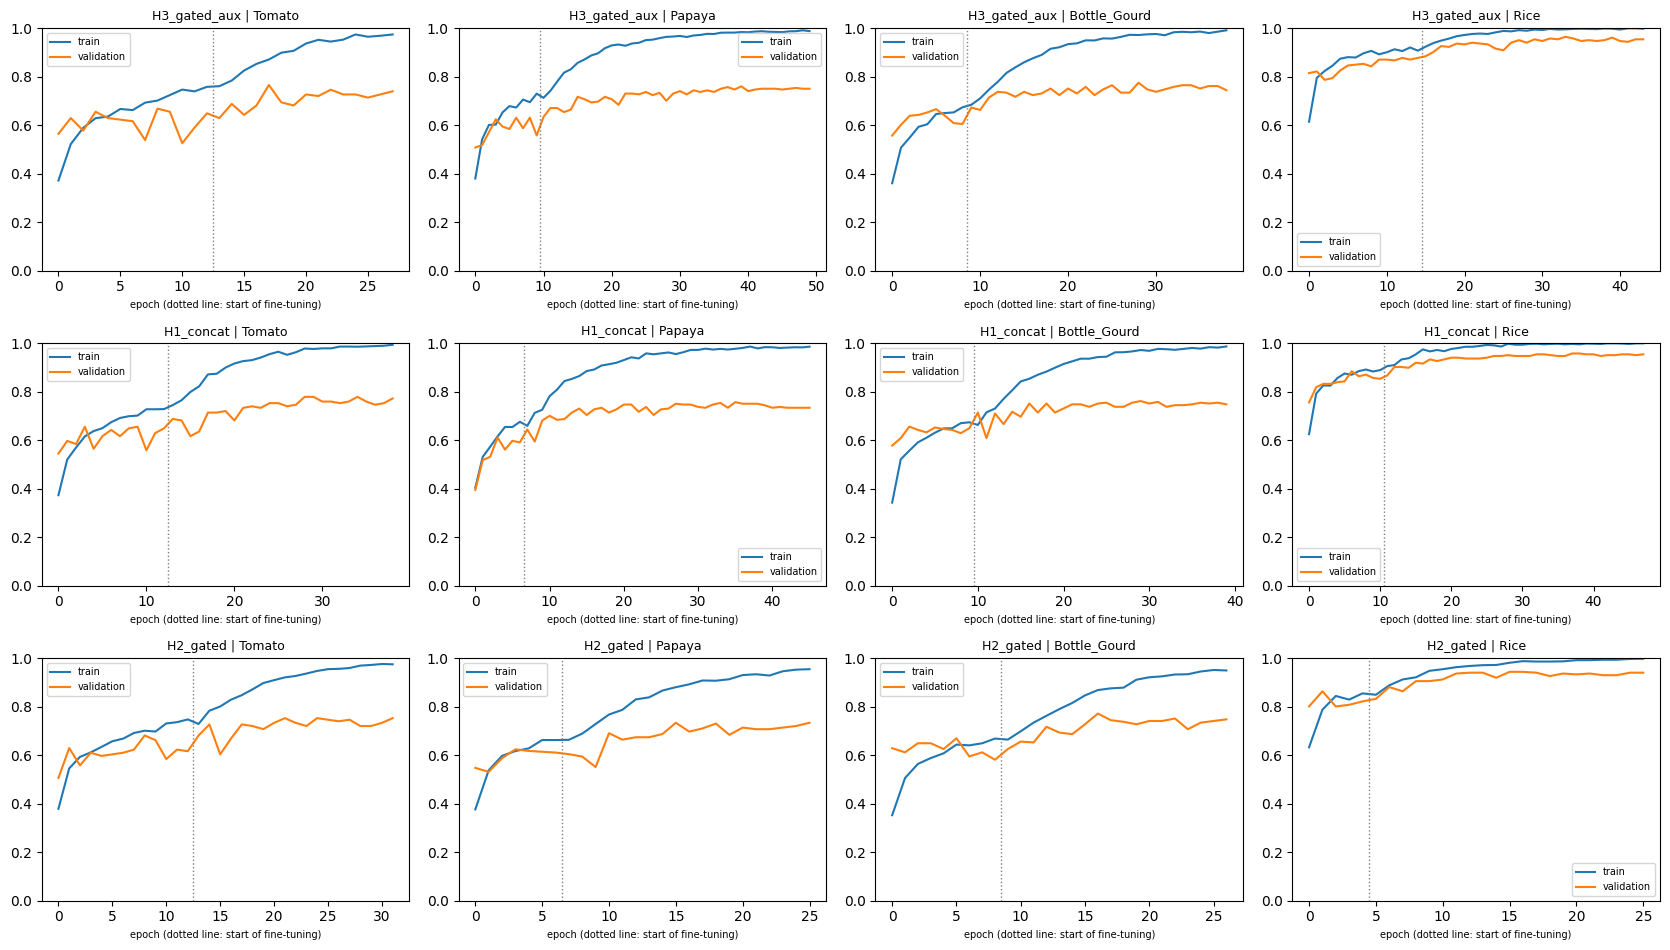

Saved /content/drive/MyDrive/thesis/experiments/hybrid_results.xlsx and figures/hybrid_training_curves.png


In [11]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(VERSIONS), len(CROPS), figsize=(4.2 * len(CROPS), 3.2 * len(VERSIONS)), squeeze=False)
for i, v in enumerate(VERSIONS):
    for j, crop in enumerate(CROPS):
        ax, f = axes[i, j], PROJECT / 'experiments' / crop.lower() / RUN_NAME / 'history' / f'{NAMES[v]}.csv'
        if f.exists():
            h = pd.read_csv(f).reset_index(drop=True)
            ax.plot(h['main_accuracy'], label='train'); ax.plot(h['val_main_accuracy'], label='validation')
            k = (h.phase == 'head').sum(); ax.axvline(k - 0.5, color='grey', ls=':', lw=1)
            ax.set_ylim(0, 1); ax.legend(fontsize=7)
        ax.set_title(f'{NAMES[v]} | {crop}', fontsize=9); ax.set_xlabel('epoch (dotted line: start of fine-tuning)', fontsize=7)
plt.tight_layout()
(PROJECT / 'figures').mkdir(exist_ok=True)
fig.savefig(PROJECT / 'figures' / 'hybrid_training_curves.png', dpi=150); plt.show()

with pd.ExcelWriter(PROJECT / 'experiments' / 'hybrid_results.xlsx') as xw:
    for title, t in tabs.items():
        t.to_excel(xw, sheet_name=title[:31])
print('Saved', PROJECT / 'experiments' / 'hybrid_results.xlsx', 'and figures/hybrid_training_curves.png')